# Q1 — Classifier Comparison on the Cardiotocography (CTG) Dataset
**IIIT Sri City — Machine Learning Assignment**

| Item | Choice |
|---|---|
| Dataset | UCI *Cardiotocography* (id 193) — 2,126 fetal CTG recordings, 21 numeric features |
| Target | `NSP` — fetal state: **N**ormal / **S**uspect / **P**athologic (3 classes) |
| Models | (a) KNN with cross-validation, (b) Decision Tree, (c) SVM with RBF kernel, (d) **Bonus:** deep 1D-CNN |
| Split | 80 % train / 20 % test, **stratified**, fixed seed |

### Design decisions (these are the things to be ready to defend in the viva)
1. **Target is `NSP`, and `CLASS` is dropped.** `CLASS` is the 10-way morphologic pattern code that is essentially a finer-grained version of the diagnosis. Using it as a feature would be *label leakage*.
2. **The classes are imbalanced** (~78 % Normal, ~14 % Suspect, ~8 % Pathologic). A model that always predicts "Normal" already gets ~78 % accuracy, so **macro-averaged** precision / recall / F1 and **one-vs-rest macro ROC-AUC** are our headline metrics. Accuracy is still reported, as the assignment asks.
3. **No test-set peeking.** All hyper-parameters are chosen by cross-validation *inside the training set*. The test set is touched once, for final evaluation.
4. **Scaling lives inside a `Pipeline`**, so inside every CV fold the scaler is fitted on the training part of that fold only (no leakage).
5. **Reproducibility:** one global seed, everything saved to `figures/q1/` and `results/`.

In [1]:
# ---------------------------------------------------------------------------
# 0. Imports, configuration, reproducibility
# ---------------------------------------------------------------------------
import os, random, warnings, time, json, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     validation_curve, learning_curve)
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, auc, confusion_matrix,
                             classification_report)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# project root = parent of notebooks/ (works whether Jupyter starts in notebooks/ or in the project root)
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
FIG_DIR, RES_DIR, DATA_DIR = f"{ROOT}/figures/q1", f"{ROOT}/results", f"{ROOT}/data"
for d in (FIG_DIR, RES_DIR):
    os.makedirs(d, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})

def savefig(name):
    plt.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device for the CNN:", DEVICE)

Device for the CNN: cpu


## 1. Load the data
We first try the official `ucimlrepo` package (needs internet). If that fails, we fall back to the file `CTG.xls` downloaded manually from the UCI page and placed in `data/`.

In [2]:
FEATURES = ['LB', 'AC', 'FM', 'UC', 'DL', 'DS', 'DP', 'ASTV', 'MSTV', 'ALTV', 'MLTV',
            'Width', 'Min', 'Max', 'Nmax', 'Nzeros', 'Mode', 'Mean', 'Median', 'Variance', 'Tendency']
CLASS_NAMES = ["Normal", "Suspect", "Pathologic"]      # NSP = 1, 2, 3  ->  0, 1, 2

def load_ctg():
    try:
        from ucimlrepo import fetch_ucirepo
        d = fetch_ucirepo(id=193)
        X = d.data.features.copy()
        y = d.data.targets["NSP"].copy()          # NOT 'CLASS'  (leakage)
        src = "ucimlrepo (UCI id=193)"
    except Exception as e:
        print(f"[info] ucimlrepo unavailable ({type(e).__name__}); using local file in data/")
        paths = sorted(glob.glob(f"{DATA_DIR}/CTG.xls*"))
        if not paths:
            raise FileNotFoundError("Put CTG.xls (from the UCI 'Cardiotocography' zip) into the data/ folder.")
        raw = pd.read_excel(paths[0], sheet_name="Data", header=None)
        # the sheet has a few junk rows above the header; locate the real header row
        hdr = raw.index[raw.apply(lambda r: ("LB" in r.values) and ("NSP" in r.values), axis=1)][0]
        raw.columns = raw.iloc[hdr].values
        raw = raw.iloc[hdr + 1:].dropna(subset=["NSP"])      # drops empty/summary rows at the bottom
        X, y = raw[FEATURES].astype(float), raw["NSP"].astype(int)
        src = paths[0]
    missing = [c for c in FEATURES if c not in X.columns]
    assert not missing, f"Missing expected columns: {missing}"
    X = X[FEATURES].astype(float).reset_index(drop=True)
    y = (y.astype(int) - 1).reset_index(drop=True)          # 0=Normal, 1=Suspect, 2=Pathologic
    return X, y, src

X, y, source = load_ctg()
print("Loaded from:", source)
print("X shape:", X.shape, "| y distribution:", y.value_counts().sort_index().to_dict())
assert X.shape[1] == 21 and set(y.unique()) == {0, 1, 2}
X.head()

Loaded from: ucimlrepo (UCI id=193)
X shape: (2126, 21) | y distribution: {0: 1655, 1: 295, 2: 176}


,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Width,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,64.0,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,130.0,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,130.0,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0


## 2. Exploratory data analysis (short but purposeful)
We check missing values, duplicates, class balance and feature correlations. These findings justify the later choices (macro metrics, scaling, regularisation).

Missing values: 0
Duplicate rows: 15 (kept; reported for transparency)


,count,mean,std,min,25%,50%,75%,max
LB,2126.0,133.304,9.841,106.0,126.000,133.000,140.000,160.000
AC,2126.0,0.003,0.004,0.0,0.000,0.002,0.006,0.019
FM,2126.0,0.009,0.047,0.0,0.000,0.000,0.003,0.481
UC,2126.0,0.004,0.003,0.0,0.002,0.004,0.007,0.015
DL,2126.0,0.002,0.003,0.0,0.000,0.000,0.003,0.015
DS,2126.0,0.000,0.000,0.0,0.000,0.000,0.000,0.001
DP,2126.0,0.000,0.001,0.0,0.000,0.000,0.000,0.005
ASTV,2126.0,46.990,17.193,12.0,32.000,49.000,61.000,87.000
MSTV,2126.0,1.333,0.883,0.2,0.700,1.200,1.700,7.000
ALTV,2126.0,9.847,18.397,0.0,0.000,0.000,11.000,91.000


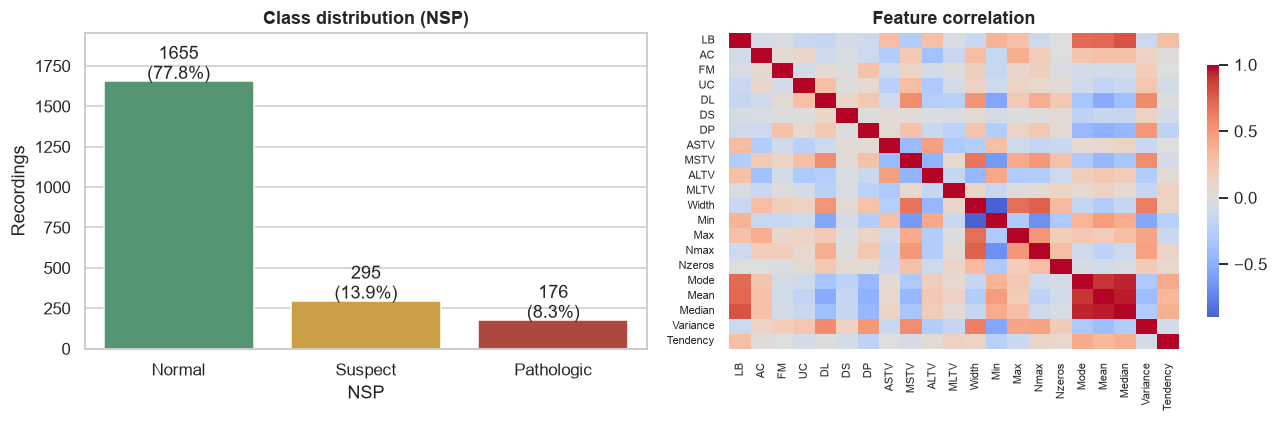

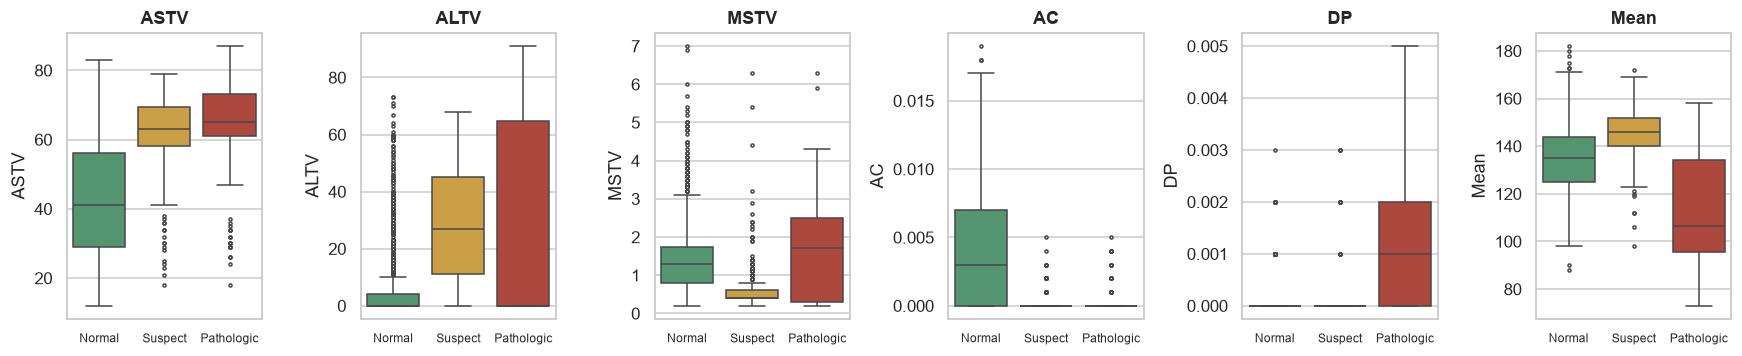

Feature pairs with |r| > 0.9 (redundant histogram statistics): [('Mode', 'Median', np.float64(0.93)), ('Mean', 'Median', np.float64(0.95))]


In [3]:
print("Missing values:", int(X.isna().sum().sum()))
print("Duplicate rows:", int(X.duplicated().sum()), "(kept; reported for transparency)")
display(X.describe().T.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = y.map(dict(enumerate(CLASS_NAMES))).value_counts().reindex(CLASS_NAMES)
sns.barplot(x=counts.index, y=counts.values, ax=axes[0], palette=["#4C9F70", "#E1A730", "#C0392B"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 15, f"{v}\n({v/len(y):.1%})", ha="center")
axes[0].set_title("Class distribution (NSP)"); axes[0].set_ylabel("Recordings"); axes[0].set_ylim(0, counts.max() * 1.18)

corr = X.corr()
sns.heatmap(corr, cmap="coolwarm", center=0, ax=axes[1], cbar_kws={"shrink": .8}, xticklabels=True, yticklabels=True)
axes[1].set_title("Feature correlation"); axes[1].tick_params(labelsize=7)
plt.tight_layout(); savefig("01_eda_class_and_corr"); plt.show()

key = ["ASTV", "ALTV", "MSTV", "AC", "DP", "Mean"]
fig, axes = plt.subplots(1, len(key), figsize=(16, 3.4))
for ax, c in zip(axes, key):
    sns.boxplot(x=y.map(dict(enumerate(CLASS_NAMES))), y=X[c], order=CLASS_NAMES, ax=ax,
                palette=["#4C9F70", "#E1A730", "#C0392B"], fliersize=2)
    ax.set_title(c); ax.set_xlabel(""); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); savefig("02_eda_feature_by_class"); plt.show()

hi = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:] if abs(corr.loc[a, b]) > 0.9]
print("Feature pairs with |r| > 0.9 (redundant histogram statistics):", hi)

## 3. Train / test split (80 / 20) and cross-validation scheme
`stratify=y` keeps the 78/14/8 class proportions identical in train and test — important because there are only ~35 Pathologic cases in the test set.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print("Train class counts:", y_train.value_counts().sort_index().to_dict())
print("Test  class counts:", y_test.value_counts().sort_index().to_dict())

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)   # used for ALL tuning
SCORING = "f1_macro"       # selection metric: robust to class imbalance
N_CLASSES = 3

Train: (1700, 21), Test: (426, 21)
Train class counts: {0: 1323, 1: 236, 2: 141}
Test  class counts: {0: 332, 1: 59, 2: 35}


## 4. Shared evaluation utilities
One set of functions is used for **all four models**, so comparisons are fair:
* `compute_metrics` → accuracy, macro precision / recall / F1, one-vs-rest macro ROC-AUC
* `plot_confusion_grid` → confusion matrices
* `macro_roc` / ROC plotting
* a **bootstrap** of the test set to put a 95 % confidence interval on ROC-AUC (with only ~35 Pathologic test cases, small AUC differences may be noise).

In [5]:
RESULTS = {}     # name -> dict(train=..., test=..., y_pred, proba, ...)

def compute_metrics(y_true, y_pred, proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "ROC-AUC (OvR macro)": roc_auc_score(y_true, proba, multi_class="ovr", average="macro"),
    }

def register(name, y_tr_pred, p_tr, y_te_pred, p_te, extra=None):
    RESULTS[name] = {
        "train": compute_metrics(y_train, y_tr_pred, p_tr),
        "test": compute_metrics(y_test, y_te_pred, p_te),
        "y_pred": np.asarray(y_te_pred), "proba": np.asarray(p_te),
        "per_class_auc": [roc_auc_score((y_test == c).astype(int), p_te[:, c]) for c in range(N_CLASSES)],
        "extra": extra or {},
    }
    t = RESULTS[name]["test"]
    print(f"[{name}]  TEST  acc={t['Accuracy']:.4f}  macro-F1={t['F1 (macro)']:.4f}  macro-AUC={t['ROC-AUC (OvR macro)']:.4f}")

def macro_roc(y_true, proba):
    """Macro-average ROC: average the per-class (one-vs-rest) TPR curves on a common FPR grid."""
    Y = label_binarize(y_true, classes=list(range(N_CLASSES)))
    grid = np.linspace(0, 1, 201); mean_tpr = np.zeros_like(grid)
    for c in range(N_CLASSES):
        fpr, tpr, _ = roc_curve(Y[:, c], proba[:, c])
        mean_tpr += np.interp(grid, fpr, tpr)
    mean_tpr /= N_CLASSES
    return grid, mean_tpr, auc(grid, mean_tpr)

def plot_confusion_grid(normalize=False, fname=None):
    names = list(RESULTS)
    fig, axes = plt.subplots(1, len(names), figsize=(4.2 * len(names), 4))
    axes = np.atleast_1d(axes)
    for ax, n in zip(axes, names):
        cm = confusion_matrix(y_test, RESULTS[n]["y_pred"], labels=[0, 1, 2])
        if normalize:
            cm_show = cm / cm.sum(axis=1, keepdims=True); fmt = ".2f"
        else:
            cm_show, fmt = cm, "d"
        sns.heatmap(cm_show, annot=True, fmt=fmt, cmap="Blues", cbar=False, ax=ax,
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, vmin=0, vmax=1 if normalize else None)
        ax.set_title(n, fontsize=11); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    fig.suptitle("Confusion matrices — " + ("row-normalised (= per-class recall)" if normalize else "counts") + " (test set)", y=1.03, fontweight="bold")
    plt.tight_layout()
    if fname: savefig(fname)
    plt.show()

COLORS = {"KNN": "#1f77b4", "Decision Tree": "#2ca02c", "SVM (RBF)": "#d62728", "1D CNN (bonus)": "#9467bd"}

## 5. Model (a) — K-Nearest Neighbours with cross-validation
**How it works:** classify a point by majority vote among its *k* closest training points. It has no training phase, so "complexity" is controlled by *k*: small *k* → very flexible, jagged boundary (**high variance / overfit**), large *k* → smooth boundary (**high bias / underfit**).
**Why scale:** KNN uses distances, so a feature measured in hundreds (e.g. `Max`) would swamp one in fractions (e.g. `AC`).
**Cross-validation:** 5-fold stratified CV on the training set selects *k*, the vote weighting and the distance metric.

KNN grid search done in 25.4s
Best params : {'knn__metric': 'manhattan', 'knn__n_neighbors': 4, 'knn__weights': 'distance'}
Best CV macro-F1: 0.8541


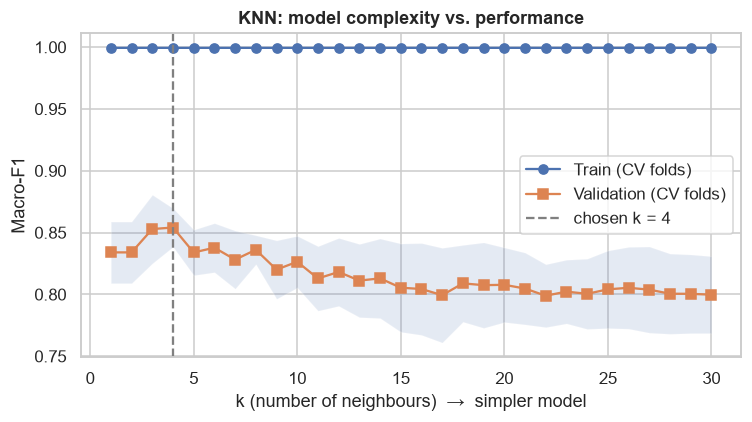

[KNN]  TEST  acc=0.9108  macro-F1=0.8255  macro-AUC=0.9531


In [6]:
t0 = time.time()
knn_pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())])
knn_grid = {"knn__n_neighbors": list(range(1, 31)),
            "knn__weights": ["uniform", "distance"],
            "knn__metric": ["euclidean", "manhattan"]}
knn_gs = GridSearchCV(knn_pipe, knn_grid, cv=CV, scoring=SCORING, n_jobs=-1, refit=True, return_train_score=True)
knn_gs.fit(X_train, y_train)
print(f"KNN grid search done in {time.time()-t0:.1f}s")
print("Best params :", knn_gs.best_params_)
print(f"Best CV macro-F1: {knn_gs.best_score_:.4f}")

# CV curve for the best weights/metric: train vs validation score as function of k
cvr = pd.DataFrame(knn_gs.cv_results_)
b = knn_gs.best_params_
sel = cvr[(cvr["param_knn__weights"] == b["knn__weights"]) & (cvr["param_knn__metric"] == b["knn__metric"])].sort_values("param_knn__n_neighbors")
plt.figure(figsize=(7, 4))
plt.plot(sel["param_knn__n_neighbors"], sel["mean_train_score"], "o-", label="Train (CV folds)")
plt.plot(sel["param_knn__n_neighbors"], sel["mean_test_score"], "s-", label="Validation (CV folds)")
plt.fill_between(sel["param_knn__n_neighbors"], sel["mean_test_score"] - sel["std_test_score"],
                 sel["mean_test_score"] + sel["std_test_score"], alpha=.15)
plt.axvline(b["knn__n_neighbors"], ls="--", c="gray", label=f"chosen k = {b['knn__n_neighbors']}")
plt.xlabel("k (number of neighbours)  →  simpler model"); plt.ylabel("Macro-F1")
plt.title("KNN: model complexity vs. performance"); plt.legend(); plt.tight_layout()
savefig("03_knn_k_curve"); plt.show()

knn_best = knn_gs.best_estimator_
register("KNN", knn_best.predict(X_train), knn_best.predict_proba(X_train),
         knn_best.predict(X_test), knn_best.predict_proba(X_test), {"best_params": {k: str(v) for k, v in b.items()}})

## 6. Model (b) — Decision Tree
**How it works:** recursively split the feature space with axis-aligned thresholds that maximise purity (Gini/entropy). Complexity is controlled by `max_depth`, `min_samples_leaf` and cost-complexity pruning `ccp_alpha`.
**No scaling needed** — splits are rank-based.
We first show the **unpruned tree** (a textbook overfitter: it can reach ~100 % training accuracy) and then the tuned tree.

Unpruned tree  → depth=14, leaves=103, train acc=0.9994, test acc=0.9014


DT grid search done in 11.3s | best: {'ccp_alpha': 0.0, 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 1} | CV macro-F1 = 0.8900


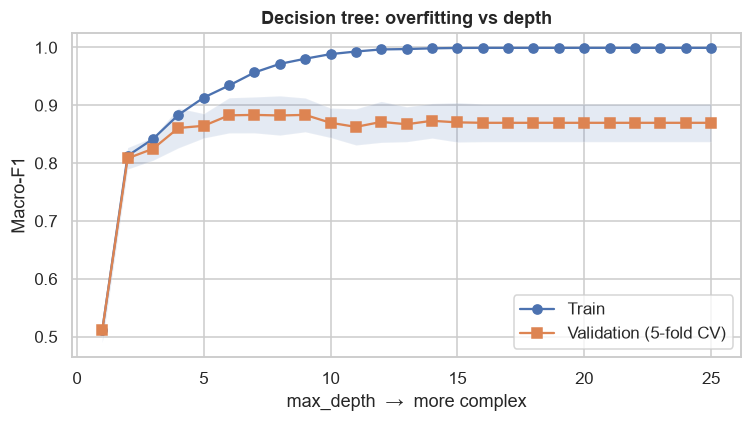

[Decision Tree]  TEST  acc=0.9155  macro-F1=0.8321  macro-AUC=0.9171


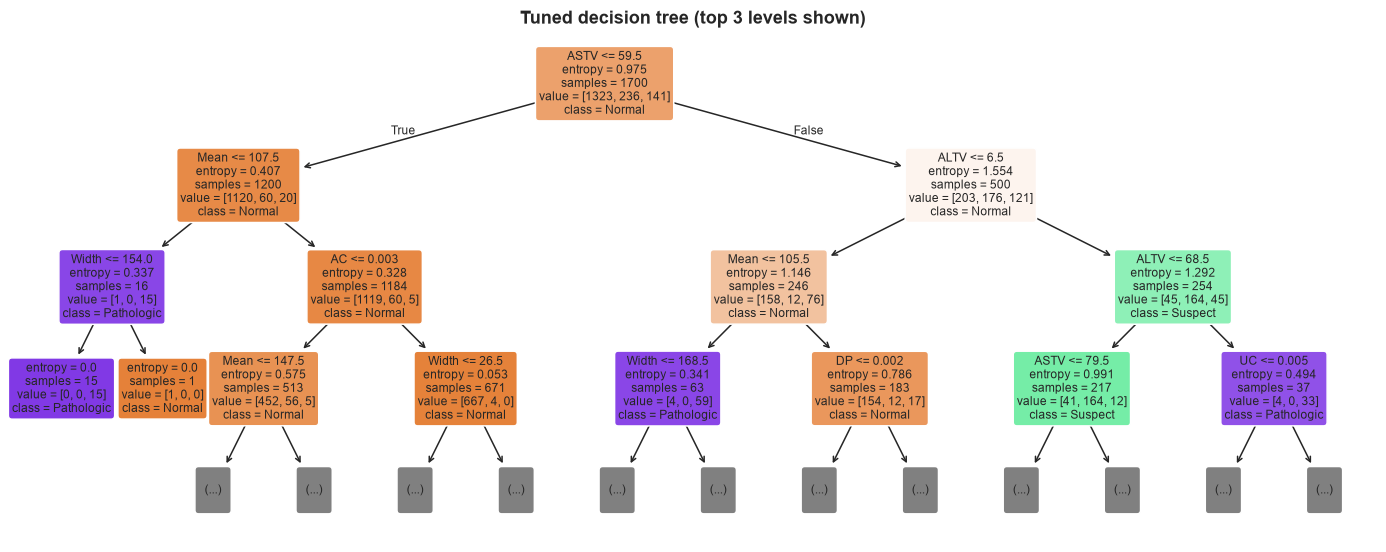

In [7]:
dt_full = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
print(f"Unpruned tree  → depth={dt_full.get_depth()}, leaves={dt_full.get_n_leaves()}, "
      f"train acc={dt_full.score(X_train, y_train):.4f}, test acc={dt_full.score(X_test, y_test):.4f}")

dt_grid = {"max_depth": list(range(2, 16)) + [None],
           "min_samples_leaf": [1, 2, 5, 10],
           "criterion": ["gini", "entropy"],
           "ccp_alpha": [0.0, 0.001, 0.005]}
t0 = time.time()
dt_gs = GridSearchCV(DecisionTreeClassifier(random_state=SEED), dt_grid, cv=CV, scoring=SCORING,
                     n_jobs=-1, refit=True, return_train_score=True)
dt_gs.fit(X_train, y_train)
print(f"DT grid search done in {time.time()-t0:.1f}s | best: {dt_gs.best_params_} | CV macro-F1 = {dt_gs.best_score_:.4f}")

# Complexity curve on TRAIN-ONLY data (validation_curve → no test leakage)
depths = list(range(1, 26))
tr_sc, va_sc = validation_curve(DecisionTreeClassifier(random_state=SEED, min_samples_leaf=1), X_train, y_train,
                                param_name="max_depth", param_range=depths, cv=CV, scoring=SCORING, n_jobs=-1)
plt.figure(figsize=(7, 4))
plt.plot(depths, tr_sc.mean(1), "o-", label="Train"); plt.plot(depths, va_sc.mean(1), "s-", label="Validation (5-fold CV)")
plt.fill_between(depths, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), alpha=.15)
plt.xlabel("max_depth  →  more complex"); plt.ylabel("Macro-F1"); plt.title("Decision tree: overfitting vs depth")
plt.legend(); plt.tight_layout(); savefig("04_dt_depth_curve"); plt.show()

dt_best = dt_gs.best_estimator_
register("Decision Tree", dt_best.predict(X_train), dt_best.predict_proba(X_train),
         dt_best.predict(X_test), dt_best.predict_proba(X_test),
         {"best_params": {k: str(v) for k, v in dt_gs.best_params_.items()},
          "unpruned_train_acc": dt_full.score(X_train, y_train), "unpruned_test_acc": dt_full.score(X_test, y_test)})

plt.figure(figsize=(16, 6))
plot_tree(dt_best, max_depth=3, feature_names=FEATURES, class_names=CLASS_NAMES, filled=True, rounded=True, fontsize=8)
plt.title("Tuned decision tree (top 3 levels shown)"); savefig("05_dt_tree_top"); plt.show()

## 7. Model (c) — Support Vector Machine with RBF kernel
**How it works:** finds the maximum-margin separator in an implicit high-dimensional space defined by the kernel $K(x,x')=\exp(-\gamma\|x-x'\|^2)$.
* **C** — penalty for margin violations. Large C → narrow margin, fits training data tightly (**overfit**); small C → wide margin (**underfit**).
* **γ** — reach of a single training point. Large γ → very local, wiggly boundary (**overfit**); small γ → nearly linear (**underfit**).
Scaling is essential (RBF is distance-based). Multi-class is handled one-vs-one internally; probabilities (needed for ROC) come from Platt scaling with `probability=True`.
*To keep the grid search fast we tune with `probability=False`, then refit the winner with `probability=True`.*

SVM grid search done in 7.1s | best: {'svm__C': 100, 'svm__gamma': 0.03} | CV macro-F1 = 0.8759


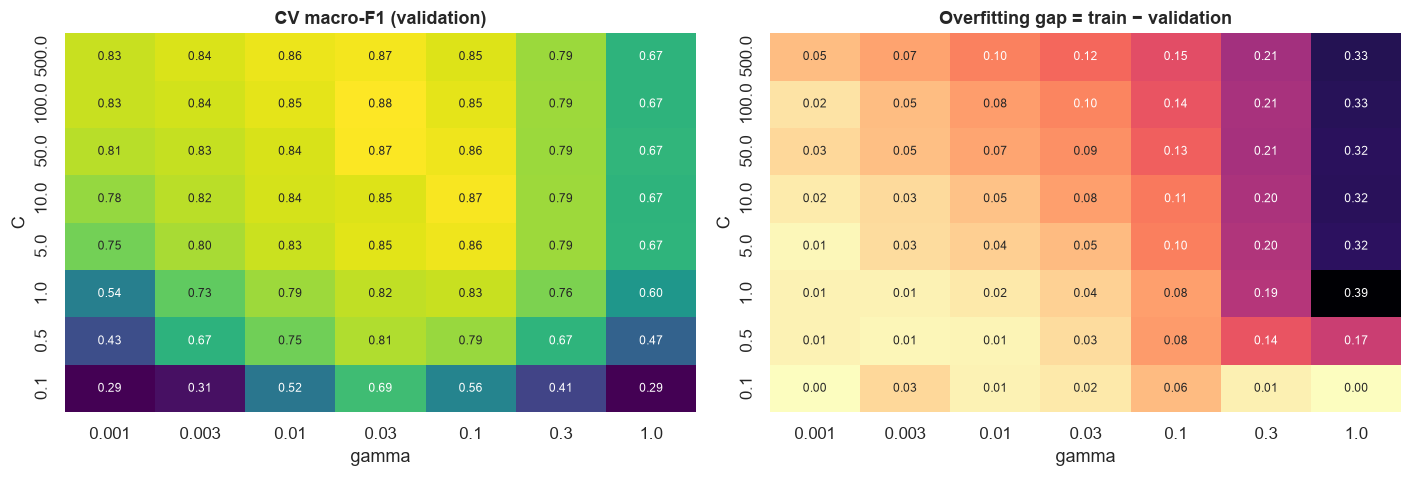

[SVM (RBF)]  TEST  acc=0.9178  macro-F1=0.8450  macro-AUC=0.9696


,SVM (as tuned),SVM + class_weight='balanced'
Macro-F1 (test),0.8450,0.8180
Recall of Pathologic class (test),0.8571,0.8571


In [8]:
svm_pipe = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="rbf", random_state=SEED))])
svm_grid = {"svm__C": [0.1, 0.5, 1, 5, 10, 50, 100, 500],
            "svm__gamma": [1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1.0]}
t0 = time.time()
svm_gs = GridSearchCV(svm_pipe, svm_grid, cv=CV, scoring=SCORING, n_jobs=-1, refit=False, return_train_score=True)
svm_gs.fit(X_train, y_train)
print(f"SVM grid search done in {time.time()-t0:.1f}s | best: {svm_gs.best_params_} | CV macro-F1 = {svm_gs.best_score_:.4f}")

# Heat-maps: validation score and train–validation gap over (C, gamma)
cvr = pd.DataFrame(svm_gs.cv_results_)
cvr["gap"] = cvr["mean_train_score"] - cvr["mean_test_score"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col, title, cmap in [(axes[0], "mean_test_score", "CV macro-F1 (validation)", "viridis"),
                             (axes[1], "gap", "Overfitting gap = train − validation", "magma_r")]:
    pv = cvr.pivot(index="param_svm__C", columns="param_svm__gamma", values=col).astype(float)
    sns.heatmap(pv, annot=True, fmt=".2f", cmap=cmap, ax=ax, cbar=False, annot_kws={"size": 8})
    ax.set_title(title); ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.invert_yaxis()
plt.tight_layout(); savefig("06_svm_C_gamma_heatmaps"); plt.show()

bp = {k.replace("svm__", ""): v for k, v in svm_gs.best_params_.items()}
svm_best = Pipeline([("scaler", StandardScaler()),
                     ("svm", SVC(kernel="rbf", probability=True, random_state=SEED, **bp))]).fit(X_train, y_train)
register("SVM (RBF)", svm_best.predict(X_train), svm_best.predict_proba(X_train),
         svm_best.predict(X_test), svm_best.predict_proba(X_test), {"best_params": {k: str(v) for k, v in bp.items()}})

# Extra ablation: does class-weighting help the minority classes?
svm_bal = Pipeline([("scaler", StandardScaler()),
                    ("svm", SVC(kernel="rbf", class_weight="balanced", random_state=SEED, **bp))]).fit(X_train, y_train)
abl = pd.DataFrame({
    "SVM (as tuned)": [f1_score(y_test, svm_best.predict(X_test), average="macro"), recall_score(y_test, svm_best.predict(X_test), average=None)[2]],
    "SVM + class_weight='balanced'": [f1_score(y_test, svm_bal.predict(X_test), average="macro"), recall_score(y_test, svm_bal.predict(X_test), average=None)[2]]},
    index=["Macro-F1 (test)", "Recall of Pathologic class (test)"]).round(4)
display(abl)

## 8. Model (d) — Deep Convolutional Neural Network (**Bonus**)
**Honest framing:** CTG is *tabular* data — the 21 features have no spatial/temporal neighbourhood structure, which is where CNNs shine. We still build a **deep 1D-CNN** that treats the 21 (standardised) features as a length-21 signal with one channel; the convolutions learn small local feature interactions, and stacked blocks give depth. We expect it to be *competitive but not necessarily better* than the SVM — and we report whatever we find.

**Architecture (6 conv layers + 2 dense):**
`[Conv1d(3)→BatchNorm→ReLU] ×2 → MaxPool → [Conv1d→BN→ReLU] ×2 → MaxPool → [Conv1d→BN→ReLU] ×2 → GlobalAvgPool → Dropout → Dense(64) → Dropout → Dense(3)`

**Regularisation against overfitting:** BatchNorm, Dropout, weight decay (AdamW), **early stopping** on a validation split carved out of the *training* set, and `ReduceLROnPlateau`.
**Imbalance:** cross-entropy with class weights inversely proportional to class frequency.
Because neural-net training is stochastic, we train with **5 seeds**: seed 42 is the reported model; mean ± std over seeds shows how stable it is.

In [9]:
class CTGConvNet(nn.Module):
    def __init__(self, n_classes=3, dropout=0.3):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(nn.Conv1d(cin, cout, kernel_size=3, padding=1), nn.BatchNorm1d(cout), nn.ReLU())
        self.features = nn.Sequential(
            block(1, 32), block(32, 32), nn.MaxPool1d(2),      # 21 -> 10
            block(32, 64), block(64, 64), nn.MaxPool1d(2),     # 10 -> 5
            block(64, 128), block(128, 128),
            nn.AdaptiveAvgPool1d(1))                           # global average pooling -> 128
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(128, 64), nn.ReLU(),
                                        nn.Dropout(dropout), nn.Linear(64, n_classes))
    def forward(self, x):                                      # x: (batch, 1, 21)
        return self.classifier(self.features(x))

print(CTGConvNet())
print("Trainable parameters:", sum(p.numel() for p in CTGConvNet().parameters() if p.requires_grad))

CTGConvNet(
  (features): Sequential(
    (0): Sequential(
      (0): Conv1d(1, 32, kernel_size=(3,), stride=(1,), padding=(1,))
      (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
    (1): Sequential(
      (0): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(1,))
      (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Sequential(
      (0): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
    (4): Sequential(
      (0): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
    (5)

In [10]:
def to_tensor(a):                       # (N, 21) -> (N, 1, 21)
    return torch.tensor(np.asarray(a), dtype=torch.float32).unsqueeze(1)

@torch.no_grad()
def cnn_proba(model, X_np):
    model.eval()
    out = []
    for i in range(0, len(X_np), 1024):
        out.append(torch.softmax(model(to_tensor(X_np[i:i + 1024]).to(DEVICE)), dim=1).cpu().numpy())
    return np.vstack(out)

def train_cnn(seed, Xa, ya, Xv, yv, max_epochs=200, patience=25, lr=1e-3, wd=1e-4, batch=64, verbose=False):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = CTGConvNet().to(DEVICE)
    counts = np.bincount(ya, minlength=N_CLASSES)
    w = torch.tensor(len(ya) / (N_CLASSES * counts), dtype=torch.float32).to(DEVICE)   # inverse-frequency weights
    crit = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=8)
    g = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(to_tensor(Xa), torch.tensor(ya, dtype=torch.long)), batch_size=batch, shuffle=True, generator=g)
    Xv_t, yv_t = to_tensor(Xv).to(DEVICE), torch.tensor(yv, dtype=torch.long).to(DEVICE)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best, best_state, bad = np.inf, None, 0
    for ep in range(max_epochs):
        model.train(); tl = tc = n = 0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(); out = model(xb); loss = crit(out, yb); loss.backward(); opt.step()
            tl += loss.item() * len(yb); tc += (out.argmax(1) == yb).sum().item(); n += len(yb)
        model.eval()
        with torch.no_grad():
            vo = model(Xv_t); vl = crit(vo, yv_t).item(); va = (vo.argmax(1) == yv_t).float().mean().item()
        sched.step(vl)
        hist["train_loss"].append(tl / n); hist["val_loss"].append(vl); hist["train_acc"].append(tc / n); hist["val_acc"].append(va)
        if vl < best - 1e-4:
            best, bad = vl, 0; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    if verbose:
        print(f"seed {seed}: stopped at epoch {ep+1}, best val loss {best:.4f}")
    return model, hist

# Pre-processing for the CNN: scaler fitted on TRAIN only; validation split taken from TRAIN only
Xtr_fit, Xtr_val, ytr_fit, ytr_val = train_test_split(X_train, y_train, test_size=0.15, stratify=y_train, random_state=SEED)
cnn_scaler = StandardScaler().fit(Xtr_fit)
A, V = cnn_scaler.transform(Xtr_fit), cnn_scaler.transform(Xtr_val)
T, TR = cnn_scaler.transform(X_test), cnn_scaler.transform(X_train)

t0 = time.time()
cnn_runs = {}
for s in [42, 43, 44, 45, 46]:
    cnn_runs[s] = train_cnn(s, A, ytr_fit.values, V, ytr_val.values, verbose=True)
print(f"CNN training (5 seeds) took {time.time()-t0:.1f}s")

seed 42: stopped at epoch 41, best val loss 0.3026


seed 43: stopped at epoch 31, best val loss 0.2610


seed 44: stopped at epoch 34, best val loss 0.3204


seed 45: stopped at epoch 36, best val loss 0.2718


seed 46: stopped at epoch 34, best val loss 0.2735
CNN training (5 seeds) took 137.0s


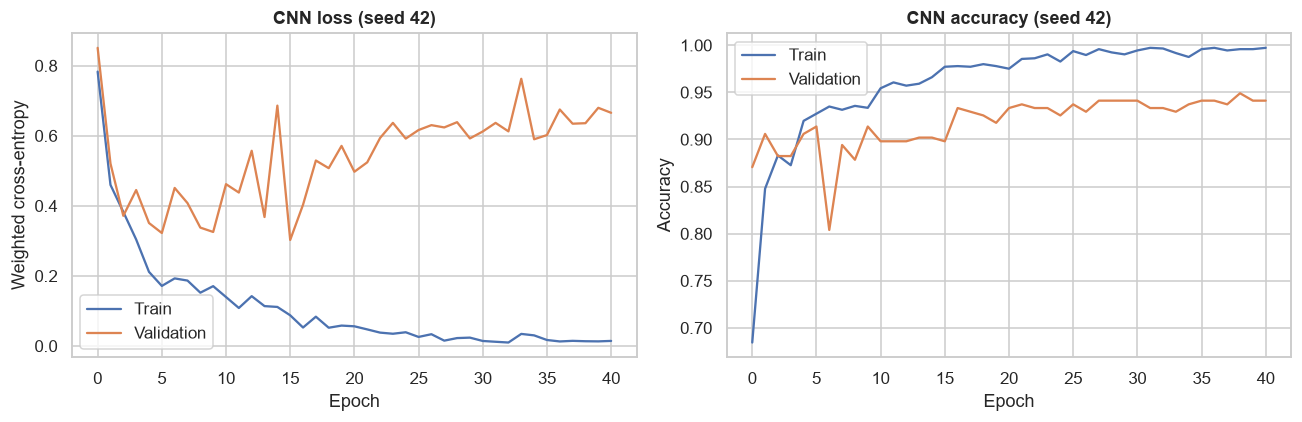

[1D CNN (bonus)]  TEST  acc=0.8826  macro-F1=0.7981  macro-AUC=0.9564


,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OvR macro),epochs
seed,,,,,,
42,0.8826,0.7538,0.8677,0.7981,0.9564,41
43,0.8709,0.7805,0.8387,0.7989,0.9654,31
44,0.8920,0.7752,0.8725,0.8161,0.9648,34
45,0.8662,0.7369,0.8576,0.7831,0.9604,36
46,0.8826,0.7645,0.8468,0.7994,0.9671,34


Mean ± std over 5 seeds:


,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OvR macro),epochs
mean,0.8789,0.7622,0.8567,0.7991,0.9628,35.2000
std,0.0103,0.0175,0.0141,0.0117,0.0044,3.7014


In [11]:
model42, hist42 = cnn_runs[42]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist42["train_loss"], label="Train"); axes[0].plot(hist42["val_loss"], label="Validation")
axes[0].set_title("CNN loss (seed 42)"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Weighted cross-entropy"); axes[0].legend()
axes[1].plot(hist42["train_acc"], label="Train"); axes[1].plot(hist42["val_acc"], label="Validation")
axes[1].set_title("CNN accuracy (seed 42)"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
plt.tight_layout(); savefig("07_cnn_training_curves"); plt.show()

p_te, p_tr = cnn_proba(model42, T), cnn_proba(model42, TR)
register("1D CNN (bonus)", p_tr.argmax(1), p_tr, p_te.argmax(1), p_te, {"epochs_trained": len(hist42["train_loss"])})

# Stability over seeds
rows = []
for s, (m, h) in cnn_runs.items():
    pt = cnn_proba(m, T); mt = compute_metrics(y_test, pt.argmax(1), pt); mt["seed"] = s; mt["epochs"] = len(h["train_loss"]); rows.append(mt)
cnn_seed_df = pd.DataFrame(rows).set_index("seed")
display(cnn_seed_df.round(4))
print("Mean ± std over 5 seeds:")
display(pd.DataFrame({"mean": cnn_seed_df.mean(), "std": cnn_seed_df.std()}).round(4).T)

## 9. Results — all four classifiers on the held-out test set
### 9.1 Confusion matrices
Counts show absolute errors; the row-normalised version equals the **per-class recall** and is the fairer view with imbalanced classes. For this medical problem the most costly error is predicting *Normal* for a *Pathologic* fetus (bottom-left of each matrix).

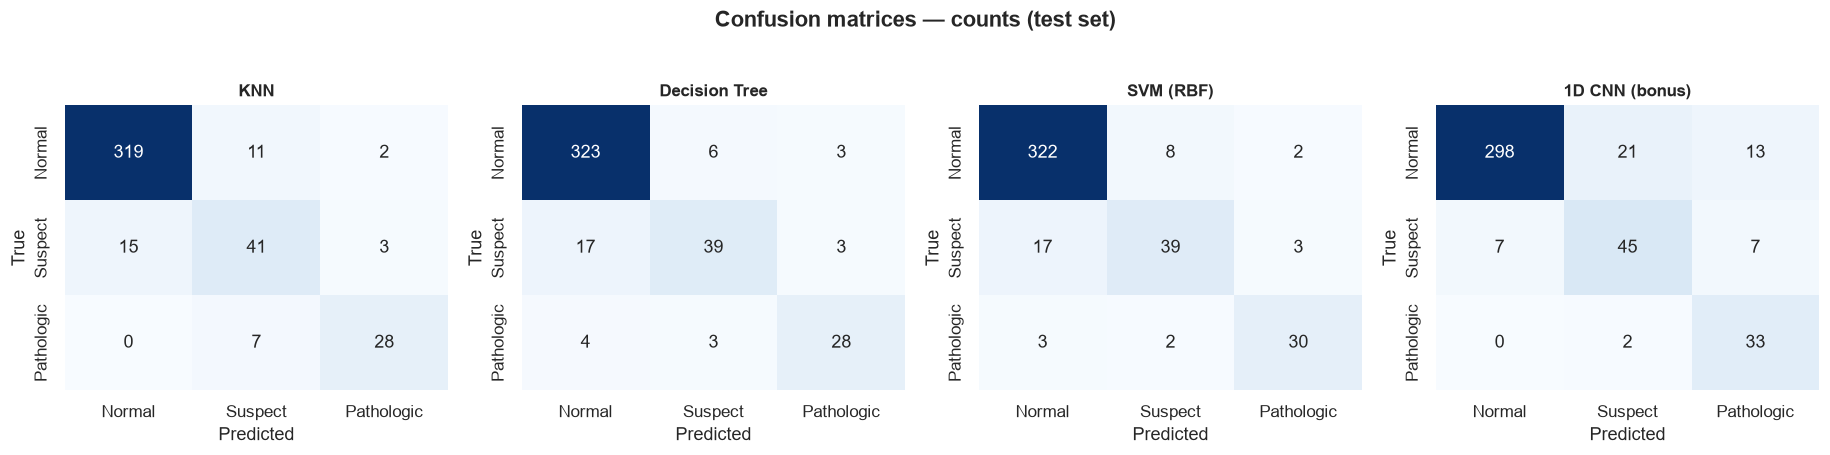

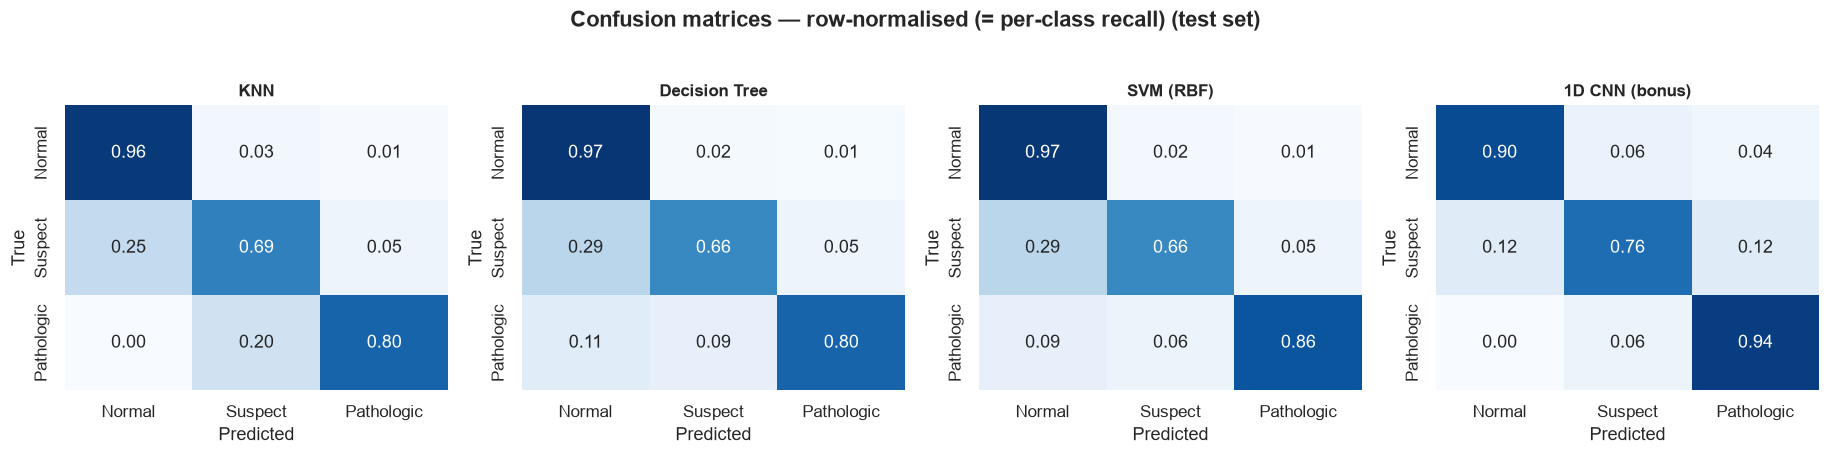

In [12]:
plot_confusion_grid(normalize=False, fname="08_confusion_counts")
plot_confusion_grid(normalize=True, fname="09_confusion_normalised")

### 9.2 Accuracy, precision, recall, F1 and ROC-AUC
*Macro* averaging computes each metric per class and takes the unweighted mean, so the small Suspect and Pathologic classes count as much as the Normal class.

TEST-set metrics


,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OvR macro)
KNN,0.9108,0.8328,0.8186,0.8255,0.9531
Decision Tree,0.9155,0.8583,0.8113,0.8321,0.9171
SVM (RBF),0.9178,0.8649,0.8293,0.8450,0.9696
1D CNN (bonus),0.8826,0.7538,0.8677,0.7981,0.9564


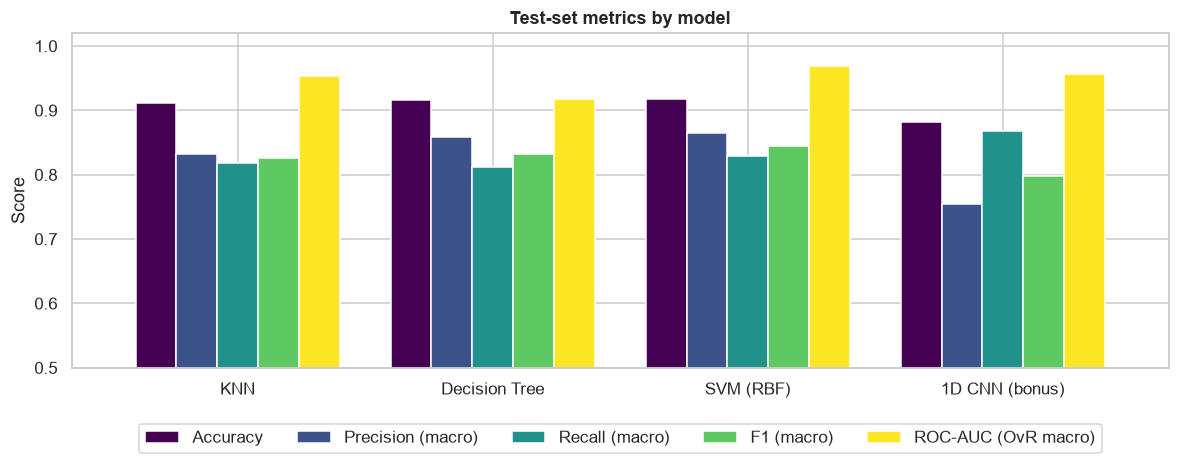


Per-class report (test set):

=== KNN ===
              precision    recall  f1-score   support

      Normal      0.955     0.961     0.958       332
     Suspect      0.695     0.695     0.695        59
  Pathologic      0.848     0.800     0.824        35

    accuracy                          0.911       426
   macro avg      0.833     0.819     0.825       426
weighted avg      0.910     0.911     0.910       426


=== Decision Tree ===
              precision    recall  f1-score   support

      Normal      0.939     0.973     0.956       332
     Suspect      0.812     0.661     0.729        59
  Pathologic      0.824     0.800     0.812        35

    accuracy                          0.915       426
   macro avg      0.858     0.811     0.832       426
weighted avg      0.912     0.915     0.912       426


=== SVM (RBF) ===
              precision    recall  f1-score   support

      Normal      0.942     0.970     0.955       332
     Suspect      0.796     0.661     0.722 

In [13]:
test_df = pd.DataFrame({n: r["test"] for n, r in RESULTS.items()}).T
train_df = pd.DataFrame({n: r["train"] for n, r in RESULTS.items()}).T
print("TEST-set metrics"); display(test_df.round(4))

ax = test_df.plot(kind="bar", figsize=(11, 4.5), width=.8, colormap="viridis")
ax.set_ylim(0.5, 1.02); ax.set_ylabel("Score"); ax.set_title("Test-set metrics by model"); plt.xticks(rotation=0)
plt.legend(loc="lower center", ncol=5, bbox_to_anchor=(.5, -.28)); plt.tight_layout(); savefig("10_metric_comparison"); plt.show()

print("\nPer-class report (test set):")
for n, r in RESULTS.items():
    print(f"\n=== {n} ==="); print(classification_report(y_test, r["y_pred"], target_names=CLASS_NAMES, digits=3, zero_division=0))

### 9.3 ROC curves and the choice of the best classifier
For three classes we use the **one-vs-rest** scheme: for each class we treat it as "positive" and the other two as "negative". We show the three per-class curves and the **macro-average** curve. A curve closer to the top-left corner (larger area) means better ranking of positives above negatives *across all thresholds* — independent of the 0.5 cut-off and of class imbalance.

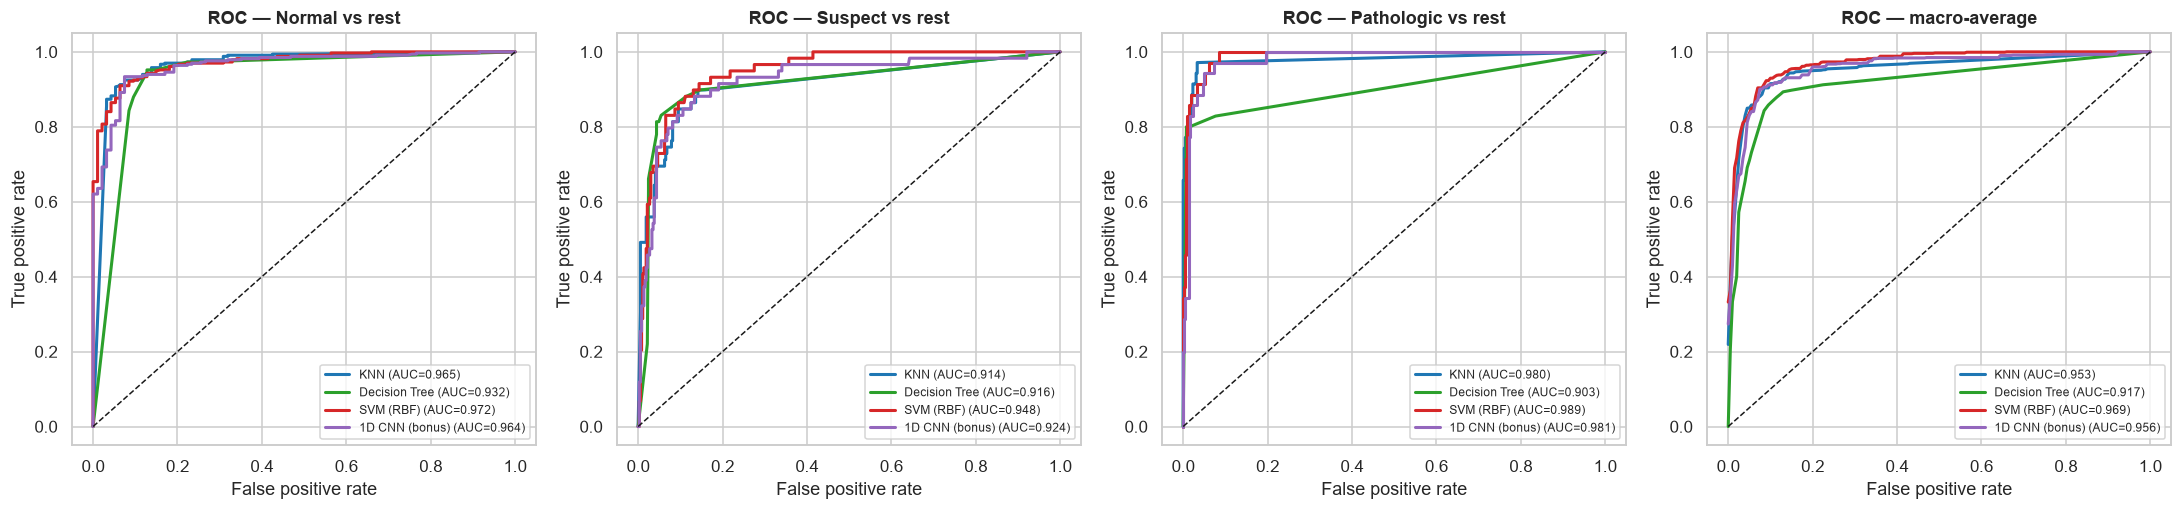

,Normal,Suspect,Pathologic,Macro
KNN,0.9651,0.9137,0.9805,0.9531
Decision Tree,0.9319,0.9161,0.9033,0.9171
SVM (RBF),0.9717,0.9481,0.9889,0.9696
1D CNN (bonus),0.9636,0.9244,0.9811,0.9564


In [14]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
for c in range(N_CLASSES):
    ax = axes[c]
    for n, r in RESULTS.items():
        fpr, tpr, _ = roc_curve((y_test == c).astype(int), r["proba"][:, c])
        ax.plot(fpr, tpr, color=COLORS[n], lw=2, label=f"{n} (AUC={r['per_class_auc'][c]:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_title(f"ROC — {CLASS_NAMES[c]} vs rest")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.legend(loc="lower right", fontsize=8)
ax = axes[3]
for n, r in RESULTS.items():
    g, t, a = macro_roc(y_test, r["proba"])
    ax.plot(g, t, color=COLORS[n], lw=2, label=f"{n} (AUC={a:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_title("ROC — macro-average"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); savefig("11_roc_curves"); plt.show()

pc_auc = pd.DataFrame({n: r["per_class_auc"] for n, r in RESULTS.items()}, index=CLASS_NAMES).T
pc_auc["Macro"] = test_df["ROC-AUC (OvR macro)"]
display(pc_auc.round(4))

In [15]:
# Bootstrap the test set → 95% CI of macro AUC, and paired CI of the difference to the best model
rng = np.random.default_rng(SEED)
B = 500
boot = {n: [] for n in RESULTS}
yt = y_test.values
for _ in range(B):
    idx = rng.integers(0, len(yt), len(yt))
    if len(np.unique(yt[idx])) < 3:
        continue
    for n, r in RESULTS.items():
        boot[n].append(roc_auc_score(yt[idx], r["proba"][idx], multi_class="ovr", average="macro"))
boot = {n: np.array(v) for n, v in boot.items()}
best_name = test_df["ROC-AUC (OvR macro)"].idxmax()
ci = pd.DataFrame({n: {"AUC": test_df.loc[n, "ROC-AUC (OvR macro)"],
                       "95% CI low": np.percentile(v, 2.5), "95% CI high": np.percentile(v, 97.5),
                       f"ΔAUC vs {best_name} (mean)": (v - boot[best_name]).mean(),
                       "Δ 95% CI low": np.percentile(v - boot[best_name], 2.5),
                       "Δ 95% CI high": np.percentile(v - boot[best_name], 97.5)} for n, v in boot.items()}).T
display(ci.round(4))

,AUC,95% CI low,95% CI high,ΔAUC vs SVM (RBF) (mean),Δ 95% CI low,Δ 95% CI high
KNN,0.9531,0.9289,0.9744,-0.0166,-0.0348,0.0007
Decision Tree,0.9171,0.8747,0.9501,-0.0536,-0.0906,-0.0220
SVM (RBF),0.9696,0.9546,0.9814,0.0000,0.0000,0.0000
1D CNN (bonus),0.9564,0.9356,0.9731,-0.0130,-0.0293,0.0009


### 9.4 Best classifier based on ROC analysis (auto-generated summary)

In [16]:
rank = test_df["ROC-AUC (OvR macro)"].sort_values(ascending=False)
print("Ranking by macro ROC-AUC (test):")
for i, (n, v) in enumerate(rank.items(), 1):
    print(f"  {i}. {n:<16} AUC = {v:.4f}   95% CI [{ci.loc[n,'95% CI low']:.3f}, {ci.loc[n,'95% CI high']:.3f}]")
print(f"\n>>> Best by ROC analysis: {best_name}")
path_col = CLASS_NAMES[2]
best_path = pc_auc[path_col].idxmax()
print(f">>> Best at detecting the clinically critical '{path_col}' class (one-vs-rest AUC): {best_path} ({pc_auc.loc[best_path, path_col]:.4f})")
overlap = [n for n in RESULTS if n != best_name and ci.loc[n, "Δ 95% CI high"] >= 0 and ci.loc[n, "Δ 95% CI low"] <= 0]
print("Models whose AUC is statistically indistinguishable from the best (paired bootstrap CI contains 0):", overlap or "none")

Ranking by macro ROC-AUC (test):
  1. SVM (RBF)        AUC = 0.9696   95% CI [0.955, 0.981]
  2. 1D CNN (bonus)   AUC = 0.9564   95% CI [0.936, 0.973]
  3. KNN              AUC = 0.9531   95% CI [0.929, 0.974]
  4. Decision Tree    AUC = 0.9171   95% CI [0.875, 0.950]

>>> Best by ROC analysis: SVM (RBF)
>>> Best at detecting the clinically critical 'Pathologic' class (one-vs-rest AUC): SVM (RBF) (0.9889)
Models whose AUC is statistically indistinguishable from the best (paired bootstrap CI contains 0): ['KNN', '1D CNN (bonus)']


## 10. Overfitting and model complexity
**Concepts.** *Underfitting* = model too simple → high error on both train and test (high **bias**). *Overfitting* = model too flexible → near-perfect train but worse test (high **variance**). The **gap** between train and test performance is the practical symptom.

**Evidence we collect:** (i) final train-vs-test gap for every model, (ii) complexity curves (done above for KNN's *k*, the tree's depth, SVM's *C* and *γ*), (iii) learning curves, (iv) CNN train/validation curves with early stopping.

In [17]:
gap = (train_df - test_df)[["Accuracy", "F1 (macro)", "ROC-AUC (OvR macro)"]].add_suffix(" gap (train−test)")
summary = pd.concat([train_df[["Accuracy", "F1 (macro)"]].add_suffix(" – train"),
                     test_df[["Accuracy", "F1 (macro)"]].add_suffix(" – test"), gap], axis=1)
display(summary.round(4))
print(f"Unpruned decision tree: train acc = {RESULTS['Decision Tree']['extra']['unpruned_train_acc']:.4f}, "
      f"test acc = {RESULTS['Decision Tree']['extra']['unpruned_test_acc']:.4f}  <- classic overfit; "
      f"tuned tree test acc = {RESULTS['Decision Tree']['test']['Accuracy']:.4f}")

,Accuracy – train,F1 (macro) – train,Accuracy – test,F1 (macro) – test,Accuracy gap (train−test),F1 (macro) gap (train−test),ROC-AUC (OvR macro) gap (train−test)
KNN,0.9994,0.9992,0.9108,0.8255,0.0886,0.1737,0.0469
Decision Tree,0.9800,0.9682,0.9155,0.8321,0.0645,0.1362,0.0813
SVM (RBF),0.9806,0.9684,0.9178,0.8450,0.0627,0.1234,0.0285
1D CNN (bonus),0.9594,0.9274,0.8826,0.7981,0.0768,0.1293,0.0409


Unpruned decision tree: train acc = 0.9994, test acc = 0.9014  <- classic overfit; tuned tree test acc = 0.9155


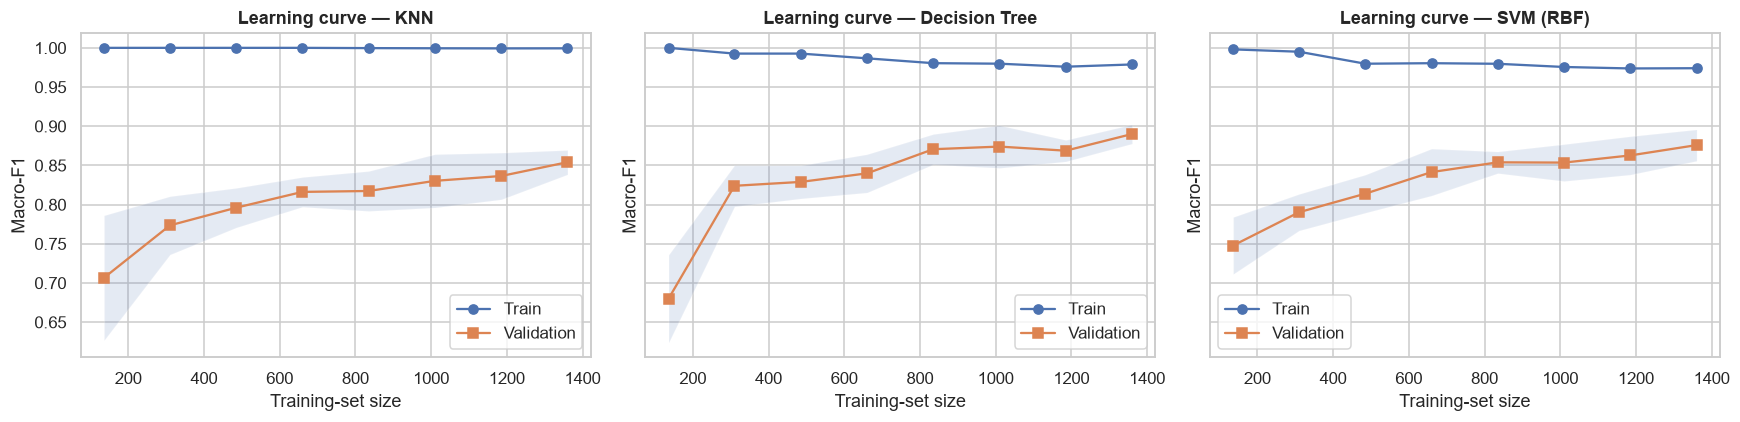

In [18]:
# Learning curves (sklearn models): does more data close the gap? (train-only data, 5-fold CV)
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
lc_models = {"KNN": knn_best,
             "Decision Tree": dt_best,
             "SVM (RBF)": Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="rbf", random_state=SEED, **bp))])}
for ax, (n, m) in zip(axes, lc_models.items()):
    sizes, tr, va = learning_curve(m, X_train, y_train, cv=CV, scoring=SCORING, train_sizes=np.linspace(.1, 1, 8), n_jobs=-1, random_state=SEED, shuffle=True)
    ax.plot(sizes, tr.mean(1), "o-", label="Train"); ax.plot(sizes, va.mean(1), "s-", label="Validation")
    ax.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=.15)
    ax.set_title(f"Learning curve — {n}"); ax.set_xlabel("Training-set size"); ax.set_ylabel("Macro-F1"); ax.legend()
plt.tight_layout(); savefig("12_learning_curves"); plt.show()

### Reading guide for the written discussion (fill in with *your* numbers after running)
* **KNN** — complexity is controlled by *k* (small *k* ⇒ overfit, train≈1.0 for *k*=1; large *k* ⇒ underfit). Note the train/validation gap in `03_knn_k_curve`.
* **Decision tree** — unpruned tree memorises the training set (train acc ≈ 100 %) but generalises worse; limiting depth / pruning (`ccp_alpha`) trades a bit of training accuracy for better test accuracy (`04_dt_depth_curve`).
* **SVM-RBF** — in `06_svm_C_gamma_heatmaps`, the bottom-right (large C *and* large γ) is the overfitting corner (large gap), the top-left is the underfitting corner (low validation score); the tuned model lies on the ridge in between.
* **CNN** — most flexible model (~hundreds of thousands of parameters vs. ~2k samples). Without regularisation it would overfit rapidly; early stopping, dropout, BN and weight decay keep the gap small. See `07_cnn_training_curves`.
* **Imbalance** — accuracy hides weak recall on Suspect/Pathologic; that's why macro-F1 and AUC are our main criteria.
* **Which is best?** Use the ROC/AUC ranking and bootstrap CIs above; mention if differences are within noise, and discuss the per-class AUC for *Pathologic*.

In [19]:
# ---------------------------------------------------------------------------
# Save everything the report needs
# ---------------------------------------------------------------------------
test_df.round(6).to_csv(f"{RES_DIR}/q1_metrics_test.csv")
train_df.round(6).to_csv(f"{RES_DIR}/q1_metrics_train.csv")
summary.round(6).to_csv(f"{RES_DIR}/q1_overfitting_summary.csv")
pc_auc.round(6).to_csv(f"{RES_DIR}/q1_per_class_auc.csv")
ci.round(6).to_csv(f"{RES_DIR}/q1_auc_bootstrap_ci.csv")
cnn_seed_df.round(6).to_csv(f"{RES_DIR}/q1_cnn_seed_stability.csv")
with open(f"{RES_DIR}/q1_best_params.json", "w") as f:
    json.dump({n: r["extra"] for n, r in RESULTS.items()} | {"best_by_roc_auc": best_name, "data_source": source,
               "n_train": int(len(X_train)), "n_test": int(len(X_test))}, f, indent=2, default=str)
print("Saved metrics to", os.path.abspath(RES_DIR), "and figures to", os.path.abspath(FIG_DIR))

Saved metrics to C:\Users\user\OneDrive\Desktop\ml_assignment\results and figures to C:\Users\user\OneDrive\Desktop\ml_assignment\figures\q1
